# RRT
From AA274A Homework 1

In [49]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [50]:
import matplotlib.pyplot as plt
import numpy as np

from cesium.planning import RRT

## Workspace

In [51]:
def box(lo, hi):
    """Returns the four walls of an axis-aligned rectangle with corners lo and hi."""
    (x0, y0), (x1, y1) = lo, hi
    return [
        ((x0, y0), (x1, y0)),
        ((x1, y0), (x1, y1)),
        ((x1, y1), (x0, y1)),
        ((x0, y1), (x0, y0)),
    ]


MAZE = np.array(
    box((0, 0), (10, 10))  # outer boundary
    + [((0, 3.5), (7, 3.5)), ((3, 6.5), (10, 6.5))]  # two long walls
    + box((7.5, 1), (8.5, 2.5))
    + box((1, 7.5), (2, 9))
    + box((4, 4.5), (5.5, 5.5))
)

# try changing these!
x_init = [1, 1]  # reset to [1, 1] when saving results for submission
x_goal = [9, 9]  # reset to [9, 9] when saving results for submission
SEED = 2000  # reset to 274 when saving results for submission

## Geometric Planning

(18, 2, 2)


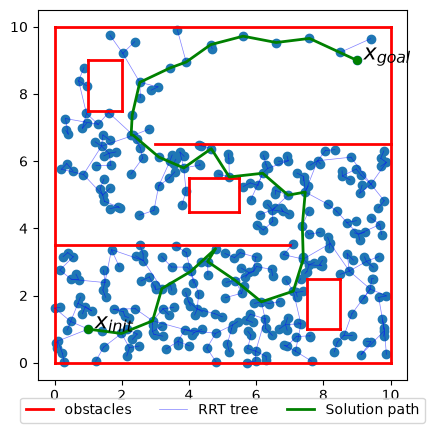

In [52]:
print(MAZE.shape)
grrt = RRT([0, 0], [10, 10], x_init, x_goal, MAZE)
grrt.solve(1, 2000, seed=SEED)

## Shortcut

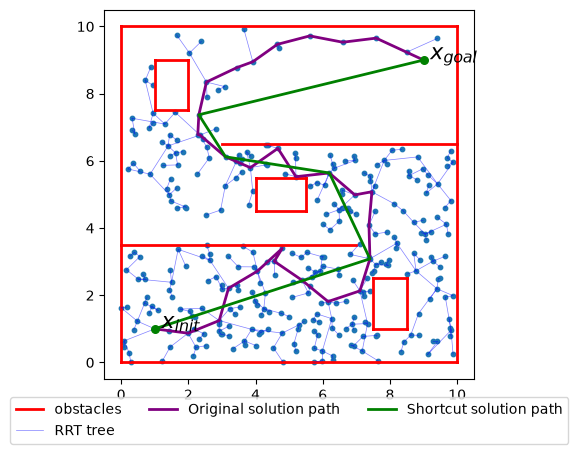

In [55]:
grrt = RRT([0, 0], [10, 10], x_init, x_goal, MAZE)
grrt.solve(1, 2000, shortcut=True, seed=SEED, s=10)

## Goal-bias experiment

This runs RRT (without plotting) 20 times for each goal-bias probability and records how often it succeeds and how many iterations it uses. It takes a minute or so to run.

goal bias | success rate | mean iterations
--------------------------------------------
     0.00 |         0.00 |          1999.0
     0.05 |         1.00 |           357.6
     0.20 |         1.00 |           406.7
     0.50 |         1.00 |           643.0
     0.90 |         0.25 |          1926.6


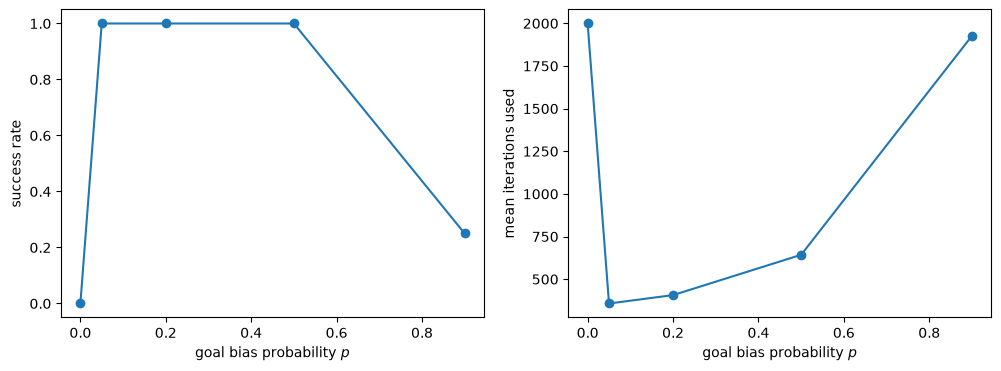

In [57]:
goal_biases = [0.0, 0.05, 0.2, 0.5, 0.9]
num_trials = 20
max_iters = 2000

np.random.seed(SEED)
success_rates, mean_iters = [], []
print(f"{'goal bias':>9} | {'success rate':>12} | {'mean iterations':>15}")
print("-" * 44)
for p in goal_biases:
    iters, successes = [], 0
    for _ in range(num_trials):
        successes += grrt.solve(1.0, max_iters, goal_bias=p, plot=False)
        iters.append(grrt.num_iters)
    success_rates.append(successes / num_trials)
    mean_iters.append(np.mean(iters))
    print(f"{p:>9.2f} | {success_rates[-1]:>12.2f} | {mean_iters[-1]:>15.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(goal_biases, success_rates, "o-")
ax1.set_xlabel("goal bias probability $p$")
ax1.set_ylabel("success rate")
ax1.set_ylim([-0.05, 1.05])
ax2.plot(goal_biases, mean_iters, "o-")
ax2.set_xlabel("goal bias probability $p$")
ax2.set_ylabel("mean iterations used")
plt.show()